# N3 — Dataset Builder

**Purpose:** Build and cache the windowed ECG training dataset from VitalDB.

**What this notebook covers:**
1. Inspect label mapping logic (`assign_label`, `get_window_label`)
2. Dry-run on 5 cases to verify window extraction and labelling
3. Full build: all 482 cases → `windows_train.npz`, `windows_val.npz`, `windows_test.npz`
4. Post-build analysis: class distribution, window counts per split

**Linked module:** `Modules/dataset_builder.py`

> **Note:** The full build downloads ~482 cases from VitalDB. This takes 20-60 minutes
> depending on your internet connection. Run the dry-run cells first to confirm everything works.

In [6]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / 'Modules'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import vitaldb

import config
from dataset_builder import (
    VitalDBDatasetBuilder, ECGWindowDataset,
    assign_label, get_window_label,
    save_array_if_not_exists, save_dataframe_if_not_exists,
)

print('Imports OK')
print(f'Annotation dir: {config.ANNOTATION_DIR}')
print(f'Output dir:     {config.OUTPUT_DATA_DIR}')


Imports OK
Annotation dir: D:\Codes\Projects\Portable_ECG_Detection_Solution\Dataset\ecg_1_lead_dataset\Annotation_Files
Output dir:     D:\Codes\Projects\Portable_ECG_Detection_Solution\Dataset\Output_Data


In [7]:
# ---- Verify label assignment logic ----
test_cases = [
    # Full names
    ('Normal Sinus Rhythm',                  False, 0),
    ('Atrial Fibrillation',                  False, 1),
    ('Supraventricular Tachyarrhythmia',     False, 2),
    ('Patterned Atrial Ectopy',              False, 2),
    ('Ventricular Tachyarrhythmia',          False, 3),
    ('Patterned Ventricular Ectopy',         False, 3),
    ('Noise',                                False, 4),
    # VitalDB abbreviations from Annotation_Files CSVs
    ('N',                                    False, 0),
    ('AFIB/AFL',                             False, 1),
    ('SVTA',                                 False, 2),
    ('WAP/MAT',                              False, 2),
    ('SND',                                  False, 2),
    ('AVB',                                  False, 2),
    ('VT',                                   False, 3),
    ('Unclassifiable',                       False, 4),
    # bad_signal_quality overrides to Noise (class 4)
    ('Normal Sinus Rhythm',                  True,  4),
    ('N',                                    True,  4),
    ('Atrial Fibrillation',                  True,  4),
    ('AFIB/AFL',                             True,  4),
]

print('assign_label() unit tests:')
all_pass = True
for rhythm, bsq, expected in test_cases:
    result = assign_label(rhythm, bsq)
    status = 'PASS' if result == expected else 'FAIL'
    if status == 'FAIL': all_pass = False
    print(f'  [{status}] rhythm={rhythm!r:45s} bsq={str(bsq):5s} -> got {result}, expected {expected}')

print('\nAll passed!' if all_pass else '\nSome tests FAILED!')


assign_label() unit tests:
  [PASS] rhythm='Normal Sinus Rhythm'                         bsq=False -> got 0, expected 0
  [PASS] rhythm='Atrial Fibrillation'                         bsq=False -> got 1, expected 1
  [PASS] rhythm='Supraventricular Tachyarrhythmia'            bsq=False -> got 2, expected 2
  [PASS] rhythm='Patterned Atrial Ectopy'                     bsq=False -> got 2, expected 2
  [PASS] rhythm='Ventricular Tachyarrhythmia'                 bsq=False -> got 3, expected 3
  [PASS] rhythm='Patterned Ventricular Ectopy'                bsq=False -> got 3, expected 3
  [PASS] rhythm='Noise'                                       bsq=False -> got 4, expected 4
  [PASS] rhythm='N'                                           bsq=False -> got 0, expected 0
  [PASS] rhythm='AFIB/AFL'                                    bsq=False -> got 1, expected 1
  [PASS] rhythm='SVTA'                                        bsq=False -> got 2, expected 2
  [PASS] rhythm='WAP/MAT'                  

In [8]:
# ---- Dry-run: process 3 cases manually ----
builder = VitalDBDatasetBuilder()
meta = pd.read_csv(config.METADATA_CSV)

# Pick 3 representative case_ids
DRY_RUN_IDS = [337, 103, 244]

for cid in DRY_RUN_IDS:
    row = meta[meta['case_id'] == cid].iloc[0]
    t_start = float(row['analysis_start_time_sec'])
    t_end   = float(row['analysis_end_time_sec'])
    print(f'\n--- Case {cid} | Rhythms: {row["rhythm_classes"]} ---')
    windows, labels = builder._process_case(cid, t_start, t_end)
    print(f'  Windows: {len(windows)}, Labels: {labels.tolist()[:20]}...')
    if len(labels) > 0:
        unique, counts = np.unique(labels, return_counts=True)
        dist = {config.CLASS_NAMES[u]: int(c) for u, c in zip(unique, counts)}
        print(f'  Class dist: {dist}')

2026-10-21 11:45:30,454 INFO Loaded metadata: 482 cases



--- Case 337 | Rhythms: N, SVTA, WAP/MAT ---
  Windows: 348, Labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]...
  Class dist: {'Normal Sinus Rhythm': 221, 'Supraventricular Arrhythmia': 109, 'Noise / Artifact': 18}

--- Case 103 | Rhythms: N, Noise, Patterned Atrial Ectopy, VT ---
  Windows: 593, Labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]...
  Class dist: {'Normal Sinus Rhythm': 413, 'Supraventricular Arrhythmia': 11, 'Ventricular Arrhythmia': 1, 'Noise / Artifact': 168}

--- Case 244 | Rhythms: N, Noise, Patterned Atrial Ectopy, Patterned Ventricular Ectopy ---
  Windows: 591, Labels: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]...
  Class dist: {'Normal Sinus Rhythm': 518, 'Supraventricular Arrhythmia': 14, 'Ventricular Arrhythmia': 37, 'Noise / Artifact': 22}


In [9]:
# ---- Preview the patient-wise split ----
splits = builder._split_case_ids()
for split_name, ids in splits.items():
    print(f'{split_name:6s}: {len(ids)} cases')

# Verify no overlap between splits
train_set = set(splits['train'])
val_set   = set(splits['val'])
test_set  = set(splits['test'])
print(f'\nTrain∩Val overlap : {len(train_set & val_set)}')   # must be 0
print(f'Train∩Test overlap: {len(train_set & test_set)}')   # must be 0
print(f'Val∩Test overlap  : {len(val_set & test_set)}')     # must be 0

train : 385 cases
val   : 48 cases
test  : 49 cases

Train∩Val overlap : 0
Train∩Test overlap: 0
Val∩Test overlap  : 0


In [ ]:
# ---- FULL BUILD (run when ready — takes 20-60 minutes) ----
# Uses Path.exists() check to skip existing splits and avoid resaving / re-downloading
# NOTE: Set force_rebuild=True if you need to re-extract windows to include newly mapped 'N' and 'AFIB/AFL' labels
FORCE_REBUILD = True

splits = ('train', 'val', 'test')
split_status = {}
for s in splits:
    p = config.OUTPUT_DATA_DIR / f'windows_{s}.npz'
    exists = p.exists()
    split_status[s] = exists
    status_str = 'EXISTS (will not resave)' if exists else 'MISSING (will download & build)'
    print(f'  {s:5s}: {status_str} -> {p}')

all_exist = all(split_status.values())
print(f'\nAll splits cached: {all_exist}')

if FORCE_REBUILD or not all_exist:
    print(f'Starting build (force_rebuild={FORCE_REBUILD})...')
    builder.build_and_cache(force_rebuild=FORCE_REBUILD)
else:
    print('Skipping build: all split files already exist. Set FORCE_REBUILD=True to rebuild.')


2026-10-21 11:47:47,967 INFO Processing split='train' (385 cases)...


  train: EXISTS (will not resave) -> D:\Codes\Projects\Portable_ECG_Detection_Solution\Dataset\Output_Data\windows_train.npz
  val  : EXISTS (will not resave) -> D:\Codes\Projects\Portable_ECG_Detection_Solution\Dataset\Output_Data\windows_val.npz
  test : EXISTS (will not resave) -> D:\Codes\Projects\Portable_ECG_Detection_Solution\Dataset\Output_Data\windows_test.npz

All splits cached: True
Starting build (force_rebuild=True)...


2026-10-21 11:48:18,398 INFO   [train] 10/385 cases done
2026-10-21 11:49:55,316 INFO   [train] 20/385 cases done


train: 38856 windows | {'Supraventricular Arrhythmia': 8122, 'Ventricular Arrhythmia': 8697, 'Noise / Artifact': 22037}
val: 4733 windows | {'Supraventricular Arrhythmia': 1380, 'Ventricular Arrhythmia': 1653, 'Noise / Artifact': 1700}
test: 3289 windows | {'Supraventricular Arrhythmia': 202, 'Ventricular Arrhythmia': 806, 'Noise / Artifact': 2281}


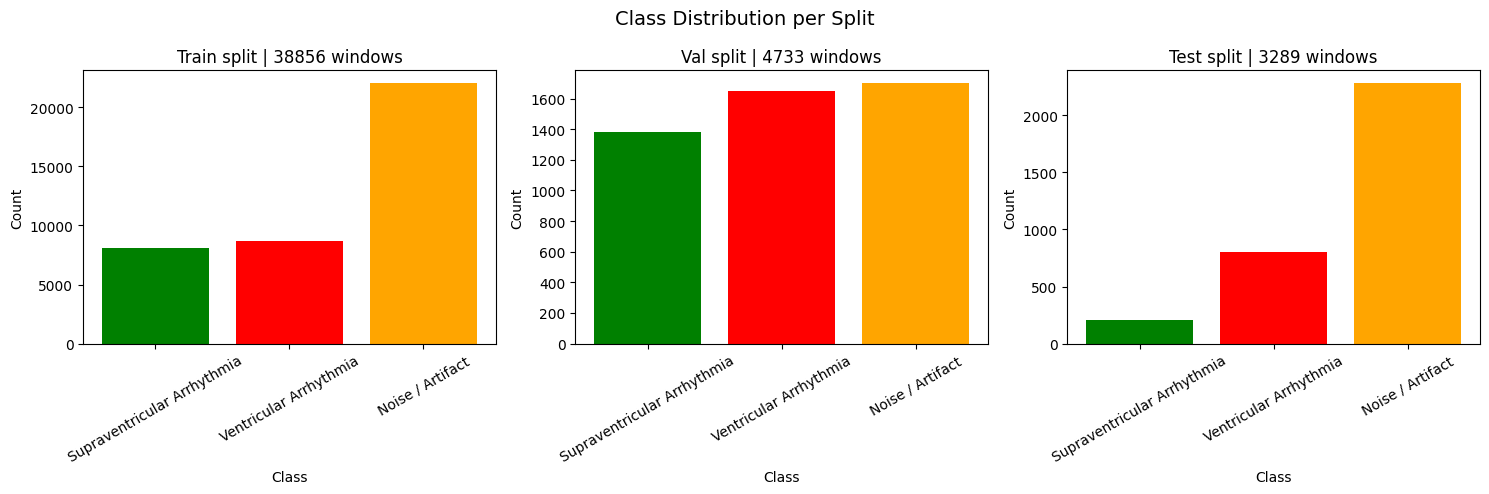

In [ ]:
# ---- Post-build: class distribution analysis ----
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, split in zip(axes, ['train', 'val', 'test']):
    npz_path = config.OUTPUT_DATA_DIR / f'windows_{split}.npz'
    if not npz_path.exists():
        ax.set_title(f'{split} (not built yet)')
        continue
    
    data = np.load(npz_path)
    y = data['y']
    unique, counts = np.unique(y, return_counts=True)
    labels = [config.CLASS_NAMES.get(int(u), f'class_{u}') for u in unique]
    
    ax.bar(labels, counts, color=['green', 'red', 'orange', 'purple', 'gray'][:len(labels)])
    ax.set_title(f'{split.capitalize()} split | {len(y)} windows')
    ax.set_xlabel('Class')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=30)
    
    print(f'{split}: {len(y)} windows | {dict(zip(labels, counts.tolist()))}')

plt.suptitle('Class Distribution per Split', fontsize=14)
plt.tight_layout()
plt.show()